<a href="https://colab.research.google.com/github/sjohn214/Colab-Repos/blob/Multi_Class_NN_Models/Third_Model_Reuters_Multi_Class_NN_Model_SLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Third NN_Model

### Reuters Newswire Multi-Class Classification Neural Network Model

# Step 1) Import Library

In [1]:
import tensorflow as tf
from tensorflow import keras
from keras import layers
from tensorflow.keras.datasets import reuters

# Step 2) Import Reuters Newswire Text Dataset

In [2]:
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(num_words=10000)

train_data

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


array([list([1, 2, 2, 8, 43, 10, 447, 5, 25, 207, 270, 5, 3095, 111, 16, 369, 186, 90, 67, 7, 89, 5, 19, 102, 6, 19, 124, 15, 90, 67, 84, 22, 482, 26, 7, 48, 4, 49, 8, 864, 39, 209, 154, 6, 151, 6, 83, 11, 15, 22, 155, 11, 15, 7, 48, 9, 4579, 1005, 504, 6, 258, 6, 272, 11, 15, 22, 134, 44, 11, 15, 16, 8, 197, 1245, 90, 67, 52, 29, 209, 30, 32, 132, 6, 109, 15, 17, 12]),
       list([1, 3267, 699, 3434, 2295, 56, 2, 7511, 9, 56, 3906, 1073, 81, 5, 1198, 57, 366, 737, 132, 20, 4093, 7, 2, 49, 2295, 2, 1037, 3267, 699, 3434, 8, 7, 10, 241, 16, 855, 129, 231, 783, 5, 4, 587, 2295, 2, 2, 775, 7, 48, 34, 191, 44, 35, 1795, 505, 17, 12]),
       list([1, 53, 12, 284, 15, 14, 272, 26, 53, 959, 32, 818, 15, 14, 272, 26, 39, 684, 70, 11, 14, 12, 3886, 18, 180, 183, 187, 70, 11, 14, 102, 32, 11, 29, 53, 44, 704, 15, 14, 19, 758, 15, 53, 959, 47, 1013, 15, 14, 19, 132, 15, 39, 965, 32, 11, 14, 147, 72, 11, 180, 183, 187, 44, 11, 14, 102, 19, 11, 123, 186, 90, 67, 960, 4, 78, 13, 68, 467, 511, 110,

In [3]:
train_data[10]

[1,
 245,
 273,
 207,
 156,
 53,
 74,
 160,
 26,
 14,
 46,
 296,
 26,
 39,
 74,
 2979,
 3554,
 14,
 46,
 4689,
 4329,
 86,
 61,
 3499,
 4795,
 14,
 61,
 451,
 4329,
 17,
 12]

In [4]:
word_index = reuters.get_word_index()
reverse_word_index = dict(
    [(value, key) for (key, value) in word_index.items()]
)

decoded_newswire = " ".join(
    [reverse_word_index.get(i - 3, "?") for i in test_data[234]]
)
print(decoded_newswire)

550378/550378 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
? european coffee roasters and traders have agreed to propose a new formula for calculating international coffee organization ico quotas dutch coffee trade association chairman chairman ? van horick said van horick who is a council member of the european coffee federation was speaking at the end of the ? annual meeting the new formula is based on six year moving averages and would give brazil the world's biggest coffee producer an unchanged quota for the remaining two years of the current coffee agreement van horick said if accepted by the consumer and producer members of the ico the formula could also be a basis for negotiating a new agreement van horick said coffee quotas were suspended in february last year when prices shot up on fears of a drought ? crop disaster in brazil although prices are now considerably lower consumers and producers have been unable to agree on re introduction brazil has been the most strongly against any change 

In [5]:
test_labels[234]

np.int64(9)

In [6]:
train_labels[10]

np.int64(3)

## Step 3) Prepare Datat for Neural Network Model Training and Testing

### Vectorize train_data and test_data

In [7]:
import numpy as np
def vectorize_sequences(sequences, dimensions=10000):
  results = np.zeros((len(sequences), dimensions))
  for i, sequence in enumerate(sequences):
    for j in sequence:
      results[i, j] = 1.
    return results

In [8]:
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

## Using tensorflow keras to encode labels

In [9]:
from tensorflow.keras.utils import to_categorical

y_train = to_categorical(train_labels)
y_test = to_categorical(test_labels)

In [10]:
y_train[12]

array([0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [11]:
y_test[20]

array([0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

## Step 4) Build NN Model

In [12]:
import tensorflow
from tensorflow import keras

multi_class_NN_Model = keras.Sequential()

multi_class_NN_Model.add(keras.layers.Dense(64, activation="relu"))
multi_class_NN_Model.add(keras.layers.Dense(64, activation="relu"))
multi_class_NN_Model.add(keras.layers.Dense(46, activation="softmax"))

In [13]:
multi_class_NN_Model.compile(optimizer="rmsprop",
                             loss="categorical_crossentropy",
                             metrics=["accuracy"])

In [14]:
x_val = x_train[:1000]
partial_x_train = x_train[1000:]

y_val = y_train[:1000]
partial_y_train = y_train[1000:]

In [15]:
partial_x_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [17]:
history = multi_class_NN_Model.fit(partial_x_train,
                                   partial_y_train,
                                   epochs = 20,
                                   batch_size = 512,
                                   validation_data = (x_val, y_val))

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - accuracy: 0.2539 - loss: 3.8120 - val_accuracy: 0.0590 - val_loss: 3.7981
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 0.2027 - loss: 3.7882 - val_accuracy: 0.3530 - val_loss: 3.7772
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 0.3514 - loss: 3.7678 - val_accuracy: 0.3530 - val_loss: 3.7572
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.3514 - loss: 3.7478 - val_accuracy: 0.3530 - val_loss: 3.7374
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.3514 - loss: 3.7281 - val_accuracy: 0.3530 - val_loss: 3.7178
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 116ms/step - accuracy: 0.3514 - loss: 3.7085 - val_accuracy: 0.3530 - val_loss: 3.6984
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 215ms/step - accuracy: 0.3514 - loss: 3.6891 - val_accuracy: 0.3530 - val_loss: 3.6792
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.3514 - loss: 3.6698 - val_accuracy: 0.3530 

In [18]:
import tensorflow.keras.layers
multi_class_NN_Model = keras.Sequential()

multi_class_NN_Model.add(keras.layers.Dense(64, activation="relu"))
multi_class_NN_Model.add(keras.layers.Dense(64, activation="relu"))
multi_class_NN_Model.add(keras.layers.Dense(46, activation="softmax"))

In [19]:
multi_class_NN_Model.compile(optimizer="rmsprop",
                             loss="categorical_crossentropy",
                             metrics=["accuracy"])

In [20]:
history_full_training = multi_class_NN_Model.fit(x_train,
                                                 y_train,
                                                 epochs = 20,
                                                 batch_size = 512)

Epoch 1/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.3326 - loss: 3.8019
Epoch 2/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.3517 - loss: 3.6871
Epoch 3/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.3517 - loss: 3.4798
Epoch 4/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.3517 - loss: 3.1860
Epoch 5/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.3517 - loss: 2.8587
Epoch 6/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.3517 - loss: 2.5908
Epoch 7/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.3517 - loss: 2.4556
Epoch 8/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.3517 - loss: 2.4197
Epoch 9/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.3517 - loss: 2.4114
Epoch 10/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.3517 - loss: 2.4076
Epoch 11/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.3517 - loss: 2.4055
Epoch 12/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy:

## Step 5) Test and Evaluate NN Model

In [21]:
multi_class_NN_Model_evaluation = multi_class_NN_Model.evaluate(x_test, y_test, verbose=0)

print("Model Test Accuracy:", multi_class_NN_Model_evaluation[1])

Model Test Accuracy: 0.36197686195373535


## Step 6) Predict using Trained NN Model

In [22]:
NN_Model_predictions = multi_class_NN_Model.predict(x_test)

71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [23]:
max_pred = (NN_Model_predictions)

In [28]:
max_pred[234]

array([0.00610133, 0.04960968, 0.00828044, 0.34899184, 0.21402551,
       0.00194621, 0.00547137, 0.00194555, 0.01565904, 0.01162354,
       0.01397043, 0.04387143, 0.00556903, 0.01958304, 0.0029022 ,
       0.00220531, 0.05006716, 0.00451106, 0.00740979, 0.05963038,
       0.03019814, 0.01129261, 0.00173432, 0.00455125, 0.00707431,
       0.01064174, 0.00269862, 0.00179999, 0.00547019, 0.00222162,
       0.00505175, 0.00443085, 0.00365632, 0.00136158, 0.00564408,
       0.00123733, 0.00552341, 0.00216269, 0.00215543, 0.00280016,
       0.00411128, 0.00335601, 0.0015251 , 0.00247273, 0.00140904,
       0.002045  ], dtype=float32)

In [29]:
max_pred_234 = np.argmax(max_pred[234])
print(max_pred_234)

3


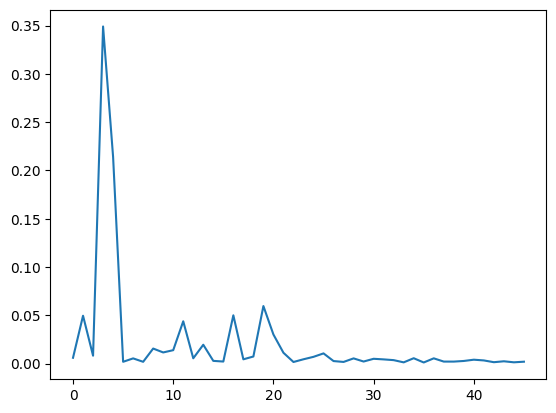

In [26]:
import matplotlib.pyplot as plt
plt.plot(max_pred[234])
plt.show()